<a href="https://colab.research.google.com/github/researchbas/javanese_word_segmentation/blob/main/Javanese_Dataset_Validation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, f1_score
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset



In [2]:
aks = [
    'ꦄ','ꦅ', 'ꦆ', 'ꦇ', 'ꦈ', 'ꦉ', 'ꦊ', 'ꦋ', 'ꦌ', 'ꦍ', 'ꦎ', 'ꦏ',
    'ꦐ', 'ꦑ', 'ꦒ', 'ꦓ', 'ꦔ', 'ꦕ', 'ꦖ', 'ꦗ', 'ꦘ', 'ꦙ', 'ꦚ', 'ꦛ', 'ꦜ','ꦝ', 'ꦞ', 'ꦟ',
    'ꦠ', 'ꦡ', 'ꦢ', 'ꦣ', 'ꦤ', 'ꦥ', 'ꦦ', 'ꦧ', 'ꦨ', 'ꦩ', 'ꦪ', 'ꦫ', 'ꦬ', 'ꦭ', 'ꦮ', 'ꦯ',
    'ꦰ', 'ꦱ', 'ꦲ'
]

def cluster(word):
    word = word.replace('-', '')
    jcc = ""
    jcc_list = []
    label_list = [1]
    flag = False
    for index, char in enumerate(word):
        jcc = jcc + char
        if index < len(word) - 1:  # Check if it's not the last character
            next_character = word[index + 1]
            if next_character in aks:
                jcc_list.append(jcc)
                label_list.append(0)
                jcc = ""
        else:
            jcc_list.append(jcc)
            jcc = ""

    return jcc_list, label_list

In [3]:
def preprocessData(data):
    X = []
    Y = []
    for text in data:
        jcc_list = []
        label_list = []
        raw = text.split("|")
        for word in raw:
            jcc, label = cluster(word)
            jcc_list.extend(jcc)
            label_list.extend(label)

        X.append(jcc_list)
        Y.append(label_list)
    return X, Y

In [4]:
expected_chars = 'ꦀꦁꦂꦃꦄꦅꦆꦇꦈꦉꦊꦋꦌꦍꦎꦏꦐꦑꦒꦓꦔꦕꦖꦗꦘꦙꦚꦛꦜꦝꦞꦟꦠꦡꦢꦣꦤꦥꦦꦧꦨꦩꦪꦫꦬꦭꦮꦯꦰꦱꦲ꦳ꦴꦵꦶꦷꦸꦹꦺꦻꦼꦽꦾꦿ꧀'
char_to_index = {char: idx for idx, char in enumerate(expected_chars)}
NUM_CHARS = len(char_to_index)

# Function to encode a character cluster
def multi_hot_encode_chars(chars):
    # print(chars)
    zero_vector = np.zeros(NUM_CHARS)
    # If the chars has fewer than max_length characters, pad with zero vectors
    for char in chars:
        zero_vector[char_to_index[char]] = 1
    return zero_vector

# Function to pad the sequences
def pad_sequences(dataset, max_sequence_length=None):
    padded_sequences = []
    if max_sequence_length is None:
        max_sequence_length = max(len(sequence) for sequence in dataset)
        print(max_sequence_length)
    for sequence in dataset:
        # Pad the sequence with zero vectors if it's shorter than max_sequence_length
        while len(sequence) < max_sequence_length:
            sequence.append(np.zeros(NUM_CHARS))  # Pad with zero vector of shape (130,)
        padded_sequences.append(sequence)
    return padded_sequences

# Function to pad labels
def pad_labels(labels, max_len=None, padding_value=-1):
    if max_len is None:
        max_len = max(len(label) for label in labels)  # Find the maximum length in the labels
    padded_labels = np.full((len(labels), max_len), padding_value)  # Assuming binary labels
    for i, label in enumerate(labels):
        padded_labels[i, :len(label)] = label  # Fill the padded array
    return padded_labels

In [5]:
import copy

# Define model
class BiLSTMModel(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers=1):
        super(BiLSTMModel, self).__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers,
                            batch_first=True, bidirectional=True)
        self.fc = nn.Linear(hidden_size * 2, 1)  # Bidirectional doubles the hidden size

    def forward(self, x):
        lstm_out, _ = self.lstm(x)  # LSTM output
        logits = self.fc(lstm_out)  # Fully connected layer output
        logits = logits.squeeze(-1)  # Remove last dimension to match the shape of labels
        return logits

# Training loop with early stopping (convergence criterion)
def train_model(model, train_dataset, val_dataset, num_epochs=100, batch_size=64,
                padding_value=-1, patience=5, min_delta=1e-3):
    """
    Convergence criterion: training stops when the validation loss has not
    improved by more than `min_delta` for `patience` consecutive epochs.
    The weights of the best epoch are restored at the end.
    """
    train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_dataloader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

    criterion = nn.BCEWithLogitsLoss(reduction='none')  # Binary cross-entropy with logits
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    # Lists to store metrics per epoch
    train_losses, val_losses = [], []
    precisions, recalls, f1_scores = [], [], []

    # Early-stopping state
    best_val_loss = float('inf')
    best_state = None
    best_epoch = 0
    epochs_no_improve = 0
    converged = False

    for epoch in range(num_epochs):
        total_train_loss = 0.0
        model.train()  # Set model to training mode
        for X_batch, Y_batch in train_dataloader:
            optimizer.zero_grad()  # Zero out gradients

            outputs = model(X_batch)  # Forward pass

            # Mask where Y_batch is not the padding value
            mask = (Y_batch != padding_value).float()

            loss = criterion(outputs, Y_batch)
            masked_loss = loss * mask

            # Average the loss only over non-padded elements
            if mask.sum() > 0:
                masked_loss = masked_loss.sum() / mask.sum()
            else:
                masked_loss = masked_loss.sum()

            masked_loss.backward()  # Backpropagation
            optimizer.step()  # Update the model parameters

            total_train_loss += masked_loss.item()  # Accumulate loss

        # Validation phase
        model.eval()  # Set model to evaluation mode
        total_val_loss = 0.0
        all_preds = []
        all_labels = []
        with torch.no_grad():
            for X_val, Y_val in val_dataloader:
                val_outputs = model(X_val)  # Forward pass
                val_mask = (Y_val != padding_value).float()
                val_loss = criterion(val_outputs, Y_val)
                masked_val_loss = val_loss * val_mask
                if val_mask.sum() > 0:
                    masked_val_loss = masked_val_loss.sum() / val_mask.sum()
                total_val_loss += masked_val_loss.item()

                # --- Collect for metrics ---
                preds = torch.sigmoid(val_outputs)  # Convert logits to probabilities
                preds = (preds > 0.5).float()       # Threshold to binary

                # Apply mask (ignore padding)
                valid_indices = (Y_val != padding_value)
                valid_preds = preds[valid_indices].cpu().numpy()
                valid_labels = Y_val[valid_indices].cpu().numpy()

                all_preds.extend(valid_preds)
                all_labels.extend(valid_labels)

        # --- Compute metrics ---
        if len(all_labels) > 0:
            precision = precision_score(all_labels, all_preds, zero_division=0)
            recall = recall_score(all_labels, all_preds, zero_division=0)
            f1 = f1_score(all_labels, all_preds, zero_division=0)
        else:
            precision = recall = f1 = 0.0

        avg_train_loss = total_train_loss / len(train_dataloader)
        avg_val_loss = total_val_loss / len(val_dataloader)

        # Store metrics
        train_losses.append(avg_train_loss)
        val_losses.append(avg_val_loss)
        precisions.append(precision)
        recalls.append(recall)
        f1_scores.append(f1)

        print(
            f"Epoch [{epoch+1}/{num_epochs}] | "
            f"Train Loss: {avg_train_loss:.4f} | "
            f"Val Loss: {avg_val_loss:.4f} | "
            f"Precision: {precision:.4f} | Recall: {recall:.4f} | F1: {f1:.4f}"
        )

        # --- Convergence check (early stopping on validation loss) ---
        if best_val_loss - avg_val_loss > min_delta:
            best_val_loss = avg_val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch + 1
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                converged = True
                print(f"Converged: validation loss did not improve by more than "
                      f"{min_delta} for {patience} consecutive epochs. "
                      f"Stopped at epoch {epoch+1}; best epoch = {best_epoch}.")
                break

    if not converged:
        print(f"Convergence criterion NOT met within {num_epochs} epochs "
              f"(best epoch = {best_epoch}).")

    # Restore the weights of the best epoch
    if best_state is not None:
        model.load_state_dict(best_state)

    # Return model + metric logs
    return model, {
        "train_loss": train_losses,
        "val_loss": val_losses,
        "val_f1": f1_scores,
        "val_precision": precisions,
        "val_recall": recalls,
        "best_epoch": best_epoch,
        "stopped_epoch": epoch + 1,
        "converged": converged,
    }

INPUT_SIZE = NUM_CHARS  # Size of the multi-hot encoded vector (65)
HIDDEN_SIZE = 128

In [10]:
##load the dataset here
df = pd.read_excel('javanese_word_segmentation.xlsx', sheet_name='Sheet1')
dataset = df['segmented_text'].head(11000).tolist()
X, Y = preprocessData(dataset)

# Step 1: split into train (80%) and temp (20%)
X_train, X_temp, Y_train, Y_temp = train_test_split(X, Y, test_size=0.2, random_state=42)
# Step 2: split temp into validation (10%) and test (10%)
X_val, X_test, Y_val, Y_test = train_test_split(X_temp, Y_temp, test_size=0.5, random_state=42)

X_train_encoded = [[multi_hot_encode_chars(jcc) for jcc in jcc_group] for jcc_group in X_train]
X_val_encoded = [[multi_hot_encode_chars(jcc) for jcc in jcc_group] for jcc_group in X_val]
X_test_encoded = [[multi_hot_encode_chars(jcc) for jcc in jcc_group] for jcc_group in X_test]

# Pad the train, val and test sequences separately
X_train_padded = pad_sequences(X_train_encoded, max(len(seq) for seq in X_train))
X_val_padded = pad_sequences(X_val_encoded, max(len(seq) for seq in X_val))
X_test_padded = pad_sequences(X_test_encoded, max(len(seq) for seq in X_test))

# Convert the padded sequences to NumPy arrays
X_train_padded_np = np.array(X_train_padded)
X_val_padded_np = np.array(X_val_padded)
X_test_padded_np = np.array(X_test_padded)

# Pad the labels
Y_train_padded = pad_labels(Y_train)
Y_val_padded = pad_labels(Y_val)
Y_test_padded = pad_labels(Y_test)

Y_train_tensor = torch.tensor(Y_train_padded, dtype=torch.float32)
Y_val_tensor = torch.tensor(Y_val_padded, dtype=torch.float32)
Y_test_tensor = torch.tensor(Y_test_padded, dtype=torch.float32)

X_train_tensor = torch.tensor(X_train_padded_np, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_padded_np, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_padded_np, dtype=torch.float32)

print(len(X_train), len(X_val), len(X_test))

8507 1063 1064


In [13]:
def class_counts(Yx):
    total = sum(len(s) for s in Yx)        # all clusters (padding not yet added)
    ones = sum(sum(s) for s in Yx)         # clusters labelled 1 (word start)
    return total, ones, total - ones

stats = {}
for name, Yx in [("training", Y_train), ("validation", Y_val), ("test", Y_test)]:
    stats[name] = class_counts(Yx)
    total, ones, zeros = stats[name]
    print(f"{name:10s} segments={len(Yx):5d} clusters={total:7d} "
          f"label1={ones:6d} ({ones/total:.1%}) label0={zeros:6d} ({zeros/total:.1%})")

# Ready-to-paste sentence
parts = []
for name, (total, ones, zeros) in stats.items():
    parts.append(f"the {name} set contains {total:,} clusters "
                 f"({ones:,} labelled 1 and {zeros:,} labelled 0)")
print("\n" + "; ".join(parts).capitalize() + ".")

training   segments= 8507 clusters= 164313 label1= 51516 (31.4%) label0=112797 (68.6%)
validation segments= 1063 clusters=  20641 label1=  6496 (31.5%) label0= 14145 (68.5%)
test       segments= 1064 clusters=  20081 label1=  6332 (31.5%) label0= 13749 (68.5%)

The training set contains 164,313 clusters (51,516 labelled 1 and 112,797 labelled 0); the validation set contains 20,641 clusters (6,496 labelled 1 and 14,145 labelled 0); the test set contains 20,081 clusters (6,332 labelled 1 and 13,749 labelled 0).


Epoch [1/100] | Train Loss: 0.5046 | Val Loss: 0.3349 | Precision: 0.7845 | Recall: 0.7483 | F1: 0.7660
Epoch [2/100] | Train Loss: 0.2795 | Val Loss: 0.2623 | Precision: 0.8625 | Recall: 0.7871 | F1: 0.8231
Epoch [3/100] | Train Loss: 0.2304 | Val Loss: 0.2274 | Precision: 0.8886 | Recall: 0.8131 | F1: 0.8492
Epoch [4/100] | Train Loss: 0.2025 | Val Loss: 0.2018 | Precision: 0.8908 | Recall: 0.8553 | F1: 0.8727
Epoch [5/100] | Train Loss: 0.1810 | Val Loss: 0.1841 | Precision: 0.8996 | Recall: 0.8707 | F1: 0.8849
Epoch [6/100] | Train Loss: 0.1626 | Val Loss: 0.1698 | Precision: 0.8967 | Recall: 0.8922 | F1: 0.8944
Epoch [7/100] | Train Loss: 0.1477 | Val Loss: 0.1547 | Precision: 0.9013 | Recall: 0.9109 | F1: 0.9061
Epoch [8/100] | Train Loss: 0.1346 | Val Loss: 0.1433 | Precision: 0.9210 | Recall: 0.9009 | F1: 0.9108
Epoch [9/100] | Train Loss: 0.1240 | Val Loss: 0.1375 | Precision: 0.9073 | Recall: 0.9286 | F1: 0.9178
Epoch [10/100] | Train Loss: 0.1150 | Val Loss: 0.1289 | Precisi

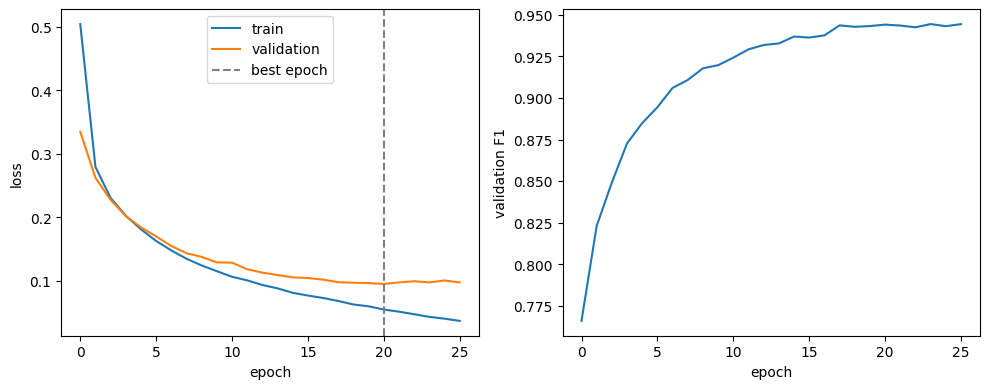

In [11]:
import matplotlib.pyplot as plt

# --- Datasets ---
train_dataset = TensorDataset(X_train_tensor, Y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, Y_val_tensor)
test_dataset = TensorDataset(X_test_tensor, Y_test_tensor)

# --- Train (early stopping on validation loss) ---
model_lstm = BiLSTMModel(input_size=INPUT_SIZE, hidden_size=HIDDEN_SIZE)
model, history = train_model(model_lstm, train_dataset, val_dataset)

print("Converged:", history["converged"],
      "| Best epoch:", history["best_epoch"],
      "| Stopped at epoch:", history["stopped_epoch"])

# --- Training curves ---
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(history["train_loss"], label="train")
ax[0].plot(history["val_loss"], label="validation")
ax[0].axvline(history["best_epoch"] - 1, ls="--", c="gray", label="best epoch")
ax[0].set_xlabel("epoch"); ax[0].set_ylabel("loss"); ax[0].legend()
ax[1].plot(history["val_f1"])
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation F1")
plt.tight_layout()
plt.savefig("training_curves.png", dpi=300)
plt.show()

In [12]:
# --- Final evaluation on the held-out test set (best-epoch weights) ---
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)

model.eval()
test_preds, test_labels = [], []
with torch.no_grad():
    for X_b, Y_b in test_loader:
        p = (torch.sigmoid(model(X_b)) > 0.5).float()
        valid = (Y_b != -1)   # ignore padding
        test_preds.extend(p[valid].cpu().numpy())
        test_labels.extend(Y_b[valid].cpu().numpy())

print("TEST  Precision: %.4f | Recall: %.4f | F1: %.4f" % (
    precision_score(test_labels, test_preds, zero_division=0),
    recall_score(test_labels, test_preds, zero_division=0),
    f1_score(test_labels, test_preds, zero_division=0)))

TEST  Precision: 0.9438 | Recall: 0.9501 | F1: 0.9470
